# 🌿 Projeto Green IT: Análise e Monitorização de Emissões de CO2 em Data Center

**Autora:** Beatriz Cavalcante de Melo  
**Área:** Data Analytics & Green IT / ESG  

---

## 📌 Descrição do Projeto
Este projeto tem como objetivo analisar e estruturar dados de consumo e emissões de carbono (CO2) gerados por serviços de infraestrutura em nuvem e data centers em diferentes regiões globais. Os dados tratados foram integrados com SQL Server Express e visualizados num dashboard executivo no Power BI.

(Fonte dos dados: Dataset público disponibilizado na plataforma Kaggle para fins de análise e estudo em Green IT / ESG).

## 🚀 Tecnologias Utilizadas:
* Linguagem: Python
* Bibliotecas: Pandas, NumPy
* Base de Dados: Microsoft SQL Server (`Sustentabilidade_DataCenter`)
* Visualização de Dados: Power BI Desktop

## 🎯 Objetivos
* Limpar, transformar e consolidar as métricas de emissão em quilogramas de CO2.
* Agregar os volumes de emissões por Região e por Serviço de nuvem.
* Exportar as estruturas consolidadas para suporte ao pipeline de BI/ESG.

## 📊 Principais Insights Obtidos
* **Regiões Críticas:** Regiões como `asia-south1` e `australia-southeast1` apresentaram os maiores volumes de emissões de CO2.
* **Serviços Impactantes:** Serviços de infraestrutura como `gke` (Google Kubernetes Engine) e consultas de dados intensivas (`bigquery`) lideraram a pegada de carbono.

In [ ]:
import pandas as pd

# Carregando o arquivo de emissões diárias
df = pd.read_csv('daily_emissions.csv')

# Exibindo as primeiras linhas para conhecermos a estrutura dos dados
display(df.head())

# Exibindo informações gerais sobre as colunas e os tipos de dados
print("\n--- Informações Gerais da Tabela ---")
df.info()

,date,project_id,service,region,usage_amount,energy_kwh,g_co2_per_kwh,emissions_kgco2
0,6/29/2025,proj-analytics,cloud_loadbalancer,europe-north1,9429.705379,0.009430,180,0.001697
1,6/29/2025,proj-analytics,vertex_ai,europe-north1,35.464027,88.660067,180,15.958812
2,6/29/2025,proj-analytics,genai_api,europe-north1,821.809856,0.016436,180,0.002959
3,6/29/2025,proj-analytics,cloud_functions,europe-north1,340.544538,0.034054,180,0.006130
4,6/29/2025,proj-analytics,compute_engine,europe-north1,59.919872,29.959936,180,5.392788



--- Informações Gerais da Tabela ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             500 non-null    object 
 1   project_id       500 non-null    object 
 2   service          500 non-null    object 
 3   region           500 non-null    object 
 4   usage_amount     500 non-null    float64
 5   energy_kwh       500 non-null    float64
 6   g_co2_per_kwh    500 non-null    int64  
 7   emissions_kgco2  500 non-null    float64
dtypes: float64(3), int64(1), object(4)
memory usage: 31.4+ KB


In [ ]:
# Agrupando os dados por região e somando o total de emissões de CO2 (em kg)
emissoes_por_regiao = df.groupby('region')['emissions_kgco2'].sum().reset_index()

# Ordenando do maior para o menor poluidor
emissoes_por_regiao = emissoes_por_regiao.sort_values(by='emissions_kgco2', ascending=False)

# Exibindo o resultado formatado
print("--- Total de Emissões de CO2 por Região ---")
display(emissoes_por_regiao)

--- Total de Emissões de CO2 por Região ---


,region,emissions_kgco2
1,asia-south1,715.442152
2,australia-southeast1,655.793706
0,asia-northeast1,561.159792
5,me-central1,560.846800
6,southamerica-east1,527.311316
8,us-east1,504.088555
7,us-central1,484.547352
4,europe-west1,336.295086
3,europe-north1,250.788573


/tmp/ipykernel_720/4093531402.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=emissoes_por_regiao, x='emissions_kgco2', y='region', palette='viridis')


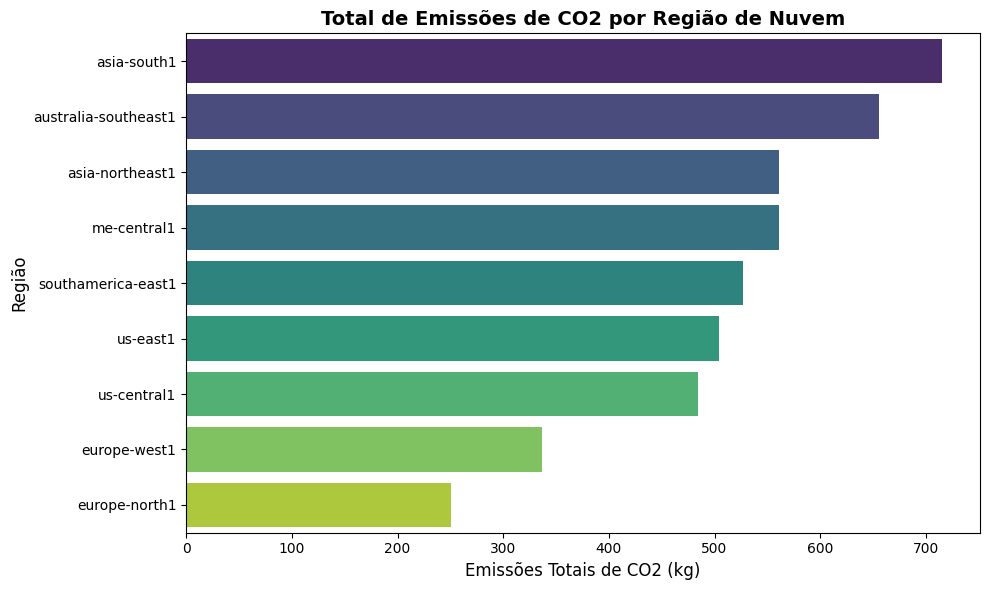

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o tamanho e o estilo visual do gráfico
plt.figure(figsize=(10, 6))
sns.barplot(data=emissoes_por_regiao, x='emissions_kgco2', y='region', palette='viridis')

# Adicionar títulos e rótulos explicativos aos eixos
plt.title('Total de Emissões de CO2 por Região de Nuvem', fontsize=14, fontweight='bold')
plt.xlabel('Emissões Totais de CO2 (kg)', fontsize=12)
plt.ylabel('Região', fontsize=12)

# Ajustar o layout para garantir uma boa visualização
plt.tight_layout()
plt.show()

In [ ]:
# Agrupando os dados por tipo de serviço de nuvem e somando as emissões de CO2
emissoes_por_servico = df.groupby('service')['emissions_kgco2'].sum().reset_index()

# Ordenando do maior para o menor poluidor
emissoes_por_servico = emissoes_por_servico.sort_values(by='emissions_kgco2', ascending=False)

# Exibindo o resultado formatado
print("--- Total de Emissões de CO2 por Tipo de Serviço ---")
display(emissoes_por_servico)

--- Total de Emissões de CO2 por Tipo de Serviço ---


,service,emissions_kgco2
9,vertex_ai,1425.306526
3,cloud_run,1425.000902
5,compute_engine,729.729589
7,gke,680.092244
0,bigquery,311.602675
4,cloud_storage,22.888185
1,cloud_functions,0.743496
8,pubsub,0.424316
6,genai_api,0.248829
2,cloud_loadbalancer,0.236569


/tmp/ipykernel_720/1528009548.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=emissoes_por_servico, x='emissions_kgco2', y='service', palette='magma')


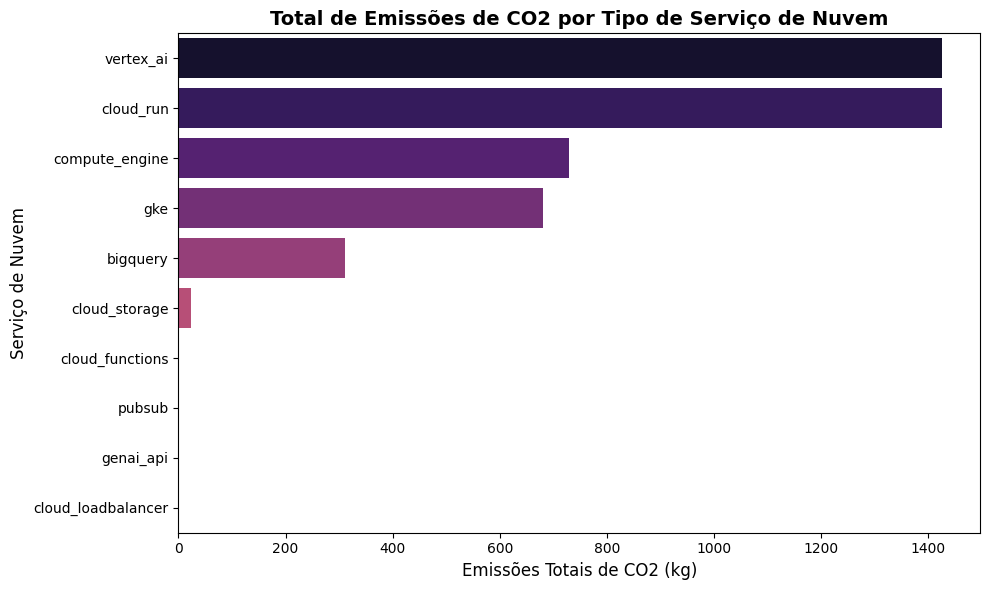

In [ ]:
# Configurando o tamanho e o estilo visual do gráfico de serviços
plt.figure(figsize=(10, 6))
sns.barplot(data=emissoes_por_servico, x='emissions_kgco2', y='service', palette='magma')

# Adicionando títulos e rótulos explicativos aos eixos
plt.title('Total de Emissões de CO2 por Tipo de Serviço de Nuvem', fontsize=14, fontweight='bold')
plt.xlabel('Emissões Totais de CO2 (kg)', fontsize=12)
plt.ylabel('Serviço de Nuvem', fontsize=12)

# Ajustando o layout
plt.tight_layout()
plt.show()

In [ ]:
# Exportar os resumos tratados para arquivos CSV
emissoes_por_regiao.to_csv('emissoes_por_regiao.csv', index=False)
emissoes_por_servico.to_csv('emissoes_por_servico.csv', index=False)

print("--- Arquivos exportados com sucesso! ---")

--- Arquivos exportados com sucesso! ---


👤Autoria

Desenvolvido por: Beatriz Cavalcante de Melo

Projeto: Green IT & ESG Data Analytics

Tecnologias: Python (Pandas) | SQL Server | Power BI
